Filename: notebook_02.ipynb <br>
Description: Dimensionality Reduction


---

Section 1: Kernel PCA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA, KernelPCA

# =====================================
# 1. Load Digits Dataset
# =====================================

digits = load_digits()

X = digits.data
y = digits.target

print("Original Data:", X.shape)

# =====================================
# 2. PCA (Linear)
# =====================================

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# =====================================
# 3. Kernel PCA (RBF)
# =====================================

kpca_rbf = KernelPCA(
    n_components=2,
    kernel='rbf',
    gamma=0.001,
    eigen_solver='arpack',
    random_state=42
)

X_rbf = kpca_rbf.fit_transform(X)

# =====================================
# 4. Kernel PCA (Polynomial)
# =====================================

kpca_poly = KernelPCA(
    n_components=2,
    kernel='poly',
    gamma=0.001,
    degree=3,
    coef0=1,
    eigen_solver='arpack'
)

X_poly = kpca_poly.fit_transform(X)

# =====================================
# 5. Visualization
# =====================================

fig = plt.figure(figsize=(20, 6))

# Reserve separate space for colorbar
gs = fig.add_gridspec(
    1, 4,
    width_ratios=[1, 1, 1, 0.04],
    wspace=0.3
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[0, 2])
]

cax = fig.add_subplot(gs[0, 3])

datasets = [
    (X_pca, 'PCA (Linear)'),
    (X_rbf, 'Kernel PCA (RBF)'),
    (X_poly, 'Kernel PCA (Polynomial)')
]

for ax, (data, title) in zip(axes, datasets):

    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=y,
        cmap='tab10',
        s=14,
        alpha=0.75,
        edgecolors='none'
    )

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Component 1', fontsize=11)
    ax.set_ylabel('Component 2', fontsize=11)
    ax.grid(alpha=0.2)

# Colorbar at the far right
cbar = fig.colorbar(scatter, cax=cax, ticks=np.arange(10))
cbar.set_label('Digit Class', fontsize=11)

fig.suptitle(
    'PCA vs Kernel PCA on Digits Dataset',
    fontsize=18,
    fontweight='bold'
)

plt.show()

# =====================================
# 6. Visualization with Digit Labels
# =====================================

fig = plt.figure(figsize=(20, 7))

gs = fig.add_gridspec(
    1, 4,
    width_ratios=[1, 1, 1, 0.04],
    wspace=0.3
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[0, 2])
]

cax = fig.add_subplot(gs[0, 3])

datasets = [
    (X_pca, 'PCA (Linear)'),
    (X_rbf, 'Kernel PCA (RBF)'),
    (X_poly, 'Kernel PCA (Polynomial)')
]

for ax, (data, title) in zip(axes, datasets):

    scatter = ax.scatter(
        data[:, 0],
        data[:, 1],
        c=y,
        cmap='tab10',
        s=14,
        alpha=0.45,
        edgecolors='none'
    )

    # Add digit labels at group centers
    for digit in np.unique(y):

        mask = y == digit

        center_x = np.median(data[mask, 0])
        center_y = np.median(data[mask, 1])

        ax.text(
            center_x,
            center_y,
            str(digit),
            fontsize=16,
            fontweight='bold',
            ha='center',
            va='center',
            color='black',
            bbox=dict(
                facecolor='white',
                edgecolor='black',
                boxstyle='circle,pad=0.35',
                alpha=0.9
            ),
            zorder=10
        )

    ax.set_title(
        title,
        fontsize=14,
        fontweight='bold'
    )

    ax.set_xlabel('Component 1')
    ax.set_ylabel('Component 2')
    ax.grid(alpha=0.2)

# Colorbar
cbar = fig.colorbar(
    scatter,
    cax=cax,
    ticks=np.arange(10)
)

cbar.set_label('Digit Class', fontsize=11)

fig.suptitle(
    'PCA vs Kernel PCA on Digits Dataset',
    fontsize=18,
    fontweight='bold'
)

plt.show()

---

Section 2: t-SNE

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.manifold import TSNE

# =====================================
# 1. Load Digits Dataset
# =====================================

digits = load_digits()

X = digits.data
y = digits.target

print("Original Shape:", X.shape)

# =====================================
# 2. Apply t-SNE
# =====================================

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

print("Reduced Shape:", X_tsne.shape)

# =====================================
# 3. Visualization
# =====================================

fig, ax = plt.subplots(figsize=(12, 8))

scatter = ax.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap='tab10',
    s=18,
    alpha=0.7,
    edgecolors='none'
)

# Add digit labels at group centers
for digit in np.unique(y):

    mask = y == digit

    center_x = np.median(X_tsne[mask, 0])
    center_y = np.median(X_tsne[mask, 1])

    ax.text(
        center_x,
        center_y,
        str(digit),
        fontsize=16,
        fontweight='bold',
        ha='center',
        va='center',
        color='black',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='circle,pad=0.4',
            alpha=0.95
        ),
        zorder=10
    )

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Digit Class', fontsize=12)
cbar.set_ticks(np.arange(10))

ax.set_title(
    't-SNE Visualization of Digits Dataset',
    fontsize=17,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('t-SNE Component 1', fontsize=12)
ax.set_ylabel('t-SNE Component 2', fontsize=12)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

---

Section 3: UMAP

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
import umap

# 1. Load Dataset
digits = load_digits()
X = digits.data
y = digits.target

print("Original Shape:", X.shape)

# 2. Apply UMAP
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42
)

X_umap = umap_model.fit_transform(X)

print("Reduced Shape:", X_umap.shape)

# 3. Visualize
fig = plt.figure(figsize=(12, 8))

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1, 0.035],
    wspace=0.12
)

ax = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[0, 1])

scatter = ax.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y,
    cmap='tab10',
    s=18,
    alpha=0.7,
    edgecolors='none'
)

# Add digit labels
for digit in np.unique(y):
    mask = y == digit

    center_x = np.median(X_umap[mask, 0])
    center_y = np.median(X_umap[mask, 1])

    ax.text(
        center_x, center_y, str(digit),
        fontsize=16,
        fontweight='bold',
        ha='center',
        va='center',
        color='black',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            boxstyle='circle,pad=0.4',
            alpha=0.95
        ),
        zorder=10
    )

# Separate Colorbar
cbar = fig.colorbar(scatter, cax=cax)
cbar.set_label('Digit Class')
cbar.set_ticks(np.arange(10))

ax.set_title(
    'UMAP Visualization of Digits Dataset',
    fontsize=17,
    fontweight='bold'
)
ax.set_xlabel('UMAP Component 1')
ax.set_ylabel('UMAP Component 2')
ax.grid(alpha=0.2)

plt.show()

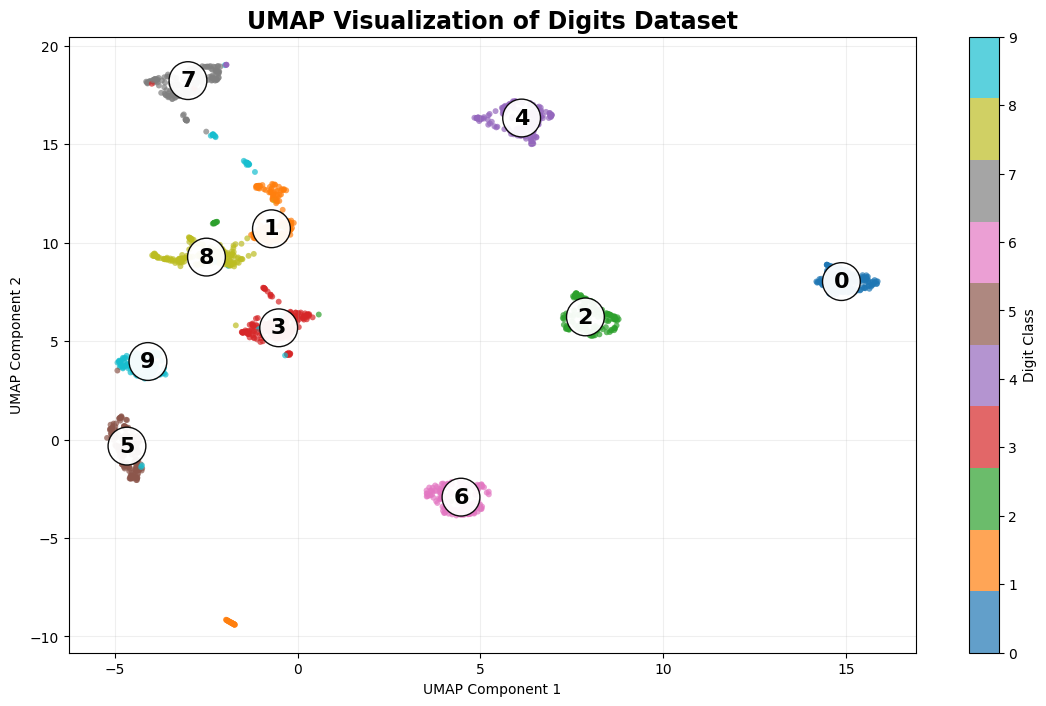

---